### Another popular outlier removal alternative: Elliptic Envelope

Elliptic Envelope seems to concentrate more on the outliers "within" the dataset instead of extreme values like Isolation Forest.

In [1]:
from sklearn.covariance import EllipticEnvelope
import pandas as pd

# contamination, same thing as in isolation
ee = EllipticEnvelope(contamination=0.005)
df = pd.read_csv("../houses.csv")

# handle these better with your own dataset, here we are simply dropping these
df = df.drop(['id', 'date', 'zipcode', 'lat', 'long'], axis=1)
y_pred = ee.fit_predict(df)
outliers = df[y_pred != 1]
inliers = df[y_pred == 1]

# Add outlier
df["outlier"] = y_pred == -1

# inliers -variables now contain the "cleaned" -version of your data
# etc. => df = inliers.copy()

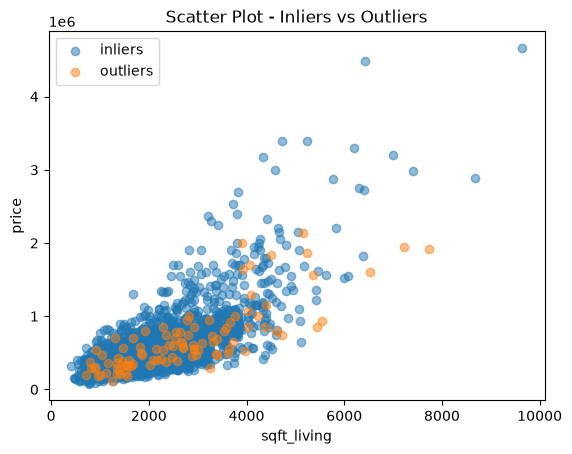

In [2]:
import matplotlib.pyplot as plt

variable = "sqft_living"
target = "price"

# if you want to reduce the number of points visualized
# sample a small amount of points, for example 300-500
inliers_sample = inliers.sample(3000)
outliers_sample = outliers.sample(100)

plt.scatter(inliers_sample[variable], inliers_sample[target], label="inliers", alpha=0.5)
plt.scatter(outliers_sample[variable], outliers_sample[target], label="outliers", alpha=0.5)

plt.xlabel(variable)
plt.ylabel(target)

plt.title("Scatter Plot - Inliers vs Outliers")
plt.legend()
plt.show()

In [ ]:
outliers

# it seems Elliptic Envelope mostly targeted houses with huge yards (sqft_lot)

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
145,921500.0,4,2.50,3670,315374,2.0,0,0,4,9,3670,0,1994,0,2840,87991
380,270000.0,2,1.50,1380,209959,1.0,0,0,1,6,1380,0,1954,0,3130,19868
929,390000.0,4,3.00,2570,262018,1.0,0,0,3,7,1420,1150,1988,0,2260,19811
1255,600000.0,2,2.50,2410,102366,1.0,0,0,4,7,1940,470,1912,1989,2460,310582
1719,700000.0,4,1.00,1300,1651359,1.0,0,3,4,6,1300,0,1920,0,2560,425581
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20452,1600000.0,4,5.50,6530,871200,2.0,0,2,3,11,6530,0,2008,0,1280,858132
20811,580000.0,3,2.50,1820,374616,2.0,0,0,3,7,1820,0,1999,0,1870,220654
20920,1830000.0,4,4.25,4500,215186,2.0,0,3,3,11,2630,1870,2009,0,3030,25447
20974,950000.0,3,2.50,2780,275033,1.0,0,0,3,10,2780,0,2006,0,1680,16340


In order to compare everything to everything, uncomment this pair plot approach.

In [4]:
# # Visualize
# import seaborn as sns
# sns.pairplot(
#     df,
#     vars=df.columns.drop("outlier"),
#     hue="outlier",
#     diag_kind="hist",
#     plot_kws={"alpha": 0.5}
# )

# plt.show()